In [1]:
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
from glaciation_time_estimator.auxiliary_func.config_reader import read_config
import numpy as np 
import pandas as pd
from cmcrameri import cm
from matplotlib.ticker import PercentFormatter
import socket 
import os

In [2]:
colormap=cm.lipariS.colors
color_dd=colormap[2]
color_sev=colormap[3]
color_mod=colormap[0]


In [3]:
years=[y for y in range(2007,2010)]
config_dd = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Validation_DARDAR/02_deg/2008_tracking/01_01.yaml")
config_mod = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Validation_MODIS/n2o_2007_01_01.yaml")

In [4]:
def return_glac_df(a):
    return a[1]
# loader_dd = ChunkLoader(years,config_dd,load_init_chunk=False)
# glac_dfs_dd = loader_dd.execute_analysis(return_glac_df,load_clouds=False)
# df_glac_dd = pd.concat(glac_dfs_dd,ignore_index=True)

# Bulk data

In [41]:
len(bulk_data_df_list)

3

In [5]:
if socket.gethostname()=='iacmac-ds4990':
    BULK_PATH = "/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/02"
else:
    BULK_PATH = "/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk_02/Bulk_statistics"
# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# iwc_rel_df_1 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2007.parquet"))
# iwc_rel_df_2 = pd.read_parquet(os.path.join(BULK_PATH,"iwc_rel_df_V3_1_2008.parquet"))
# mean_iwc_by_height_df = pd.read_parquet(os.path.join(BULK_PATH,"mean_iwc_by_height_data_V3_1_2007.parquet"))
# iwc_rel_df_loaded = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

bulk_data_df_list=[]
for year in range(2007,2011):
    if year == 2010:
        continue
    bulk_data_df_list.append(pd.read_parquet(os.path.join(BULK_PATH,f"glaciations_with_bulk_data_V3_1_{year}.parquet")))

bulk_data_df = pd.concat(bulk_data_df_list, ignore_index=True)

# bulk_data_df = pd.read_parquet(os.path.join(BULK_PATH,"glaciations_with_bulk_data_V3_1_2007.parquet"))
# bulk_data_debug = pd.read_parquet(os.path.join("/Volumes/University_stuff/Code_Projects/MSGI/Bulk_data/glaciations_with_bulk_data_V3_1_2007.parquet"))

# Filter rows with no measurements (Cehck why are there such???)
bulk_data_df=bulk_data_df[bulk_data_df.apply(lambda row: not (len(row["bulk_height_means_m"])==0) , axis=1)]
## Split cells by pass
ROWS_1D=["ddc_cloud_top_temp_means_K","ddc_cloud_top_height_means_m", "iwc_top_means", "colocation_time"]
import numpy as np
import pandas as pd


def is_pass_list(x):
    """
    True if x looks like a per-pass list/array:
    e.g. [pass1, pass2] where each pass may itself be a list/array.
    """
    if isinstance(x, np.ndarray):
        return isinstance(x[0], np.ndarray)

    return False


def split_rows_by_pass(df, reference_col="bulk_height_means_m"):
    new_rows = []

    for _, row in df.iterrows():
        ref_val = row[reference_col]

        # Number of passes, e.g. len([[...], [...]]) == 2
        if is_pass_list(ref_val):
            n_passes = len(ref_val)
        else:
            n_passes = 1
        for pass_i in range(n_passes):
            new_row = {}

            for col in df.columns:
                val = row[col]
                # If this column contains per-pass values, take the matching pass
                if is_pass_list(val):
                    if pass_i < len(val):
                        new_row[col] = val[pass_i]
                    else:
                        # Leave empty if this column does not have this pass
                        new_row[col] = np.nan
                elif col in ROWS_1D:
                    new_row[col] = val[pass_i]
                else:
                    # Scalar / non-list values are copied to every split row
                    new_row[col] = val
                


            new_rows.append(new_row)

    return pd.DataFrame(new_rows, columns=df.columns)

# row = 

bulk_data_df_split = split_rows_by_pass(
    bulk_data_df,
    reference_col="bulk_height_means_m"
)
bulk_data_df_split = bulk_data_df_split[(bulk_data_df_split["avg_ctt"].isna()) | (((bulk_data_df_split["avg_ctt"]-273.15)<0) & ((bulk_data_df_split["avg_ctt"]-273.15)>-36))]

## Stats by relative time
ORIGINAL_VALID_CLOUD_COLUMNS = bulk_data_df.columns.tolist()

bulk_data_df_split["rel_ind"] = bulk_data_df_split.apply(
    lambda row: int(round(
        (pd.Timestamp(row["colocation_time"]) - row["track_start_time"]) / pd.Timedelta(minutes=15)
    )) - int(row["Glac_peak_ind"]),
    axis=1
)
bulk_data_df_split["rel_time_min"] = bulk_data_df_split["rel_ind"]*15
sample = bulk_data_df_split.sample(100, random_state=1)
def generate_stats_by_rel_time(df, mode="mean"):
    if mode == "mean":
        stats_by_rel_time = (
            df
            .groupby("rel_ind")
            .agg(
                n_hits=("iwc_bulk_means", "count"),

                mean_iwc_profile=(
                    "iwc_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_Z_profile=(
                    "Z_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_ext_profile=(
                    "ext_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),
                mean_temp_profile=(
                    "temp_bulk_means",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                mean_bulk_height_profile_m=(
                    "bulk_level_offset_mid_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_top_m=(
                    "bulk_level_offset_top_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                bulk_offset_bottom_m=(
                    "bulk_level_offset_bottom_m",
                    lambda profiles: np.nanmean(np.stack(profiles), axis=0),
                ),

                dd_cth=(
                    "ddc_cloud_top_height_means_m",
                    "mean",
                ),

                sev_cth=(
                    "avg_cth",
                    "mean",
                ),

                dd_ctt=(
                    "ddc_cloud_top_temp_means_K",
                    "mean",
                ),

                mean_iwc_ct=(
                    "iwc_top_means",
                    "mean",
                ),

                sev_ctt=(
                    "avg_ctt",
                    "mean",
                ),
                
                mean_area_km=(
                    "avg_size[km]",
                    "mean",
                ),
                
            )
            .reset_index()
        )
    elif mode=="median":
        print("Calculating median")
        stats_by_rel_time = (
        df
        .groupby("rel_ind")
        .agg(
            n_hits=("iwc_bulk_means", "count"),

            mean_iwc_profile=(
                "iwc_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_Z_profile=(
                "Z_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_ext_profile=(
                "ext_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),
            mean_temp_profile=(
                "temp_bulk_means",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            mean_bulk_height_profile_m=(
                "bulk_level_offset_mid_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_top_m=(
                "bulk_level_offset_top_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            bulk_offset_bottom_m=(
                "bulk_level_offset_bottom_m",
                lambda profiles: np.nanmedian(np.stack(profiles), axis=0),
            ),

            dd_cth=(
                "ddc_cloud_top_height_means_m",
                "median",
            ),

            sev_cth=(
                "avg_cth",
                "median",
            ),

            dd_ctt=(
                "ddc_cloud_top_temp_means_K",
                "median",
            ),

            mean_iwc_ct=(
                "iwc_top_means",
                "median",
            ),


            sev_ctt=(
                "avg_ctt",
                "median",
            ),
            
            mean_area_km=(
                "avg_size[km]",
                "median",
            ),
            
            )
            .reset_index()
        )
    else:
        raise ValueError("Set statistics 'MODE' to mean or median")
    stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15
    return stats_by_rel_time

In [ ]:
# def calculate_top_depth(row):
#     tot_thickness = 0
#     small_ext_counter = 0
#     for j, ext in enumerate(row["ext_bulk_means"]):
#         lev_depth = row.bulk_level_offset_top_m[j]-row.bulk_level_offset_bottom_m[j]
#         tot_thickness += lev_depth*ext
#         if ext<2.0e-4:
#             small_ext_counter+=1
#         if tot_thickness>=0.2:
#             # print(tot_thickness,j*120,small_ext_counter*120)
#             return j*120
#     return None
        
            
# sample["ct_depth"] = sample.apply(calculate_top_depth,axis=1)
# (sample["ct_depth"]>600).value_counts()
def optical_depth_path(row):
    if row.bulk_level_offset_top_m is None:
        return None

    z_top = np.asarray(row.bulk_level_offset_top_m, dtype=float)
    z_bottom = np.asarray(row.bulk_level_offset_bottom_m, dtype=float)
    ext = np.asarray(row["ext_bulk_means"], dtype=float)

    dz = np.abs(z_top - z_bottom)

    # optional safety check
    if len(dz) != len(ext):
        raise ValueError(
            f"Length mismatch: dz has {len(dz)} layers, extinction has {len(ext)} values"
        )

    tau_path = [0.0]
    depth_path = [0.0]

    tau = 0.0
    depth = 0.0

    for layer_dz, layer_ext in zip(dz, ext):
        layer_tau = layer_dz * layer_ext

        tau += layer_tau
        depth += layer_dz

        tau_path.append(tau)
        depth_path.append(depth)

    return {
        "depth_m": np.asarray(depth_path),
        "tau": np.asarray(tau_path)
    }

def calculate_ct_depth(row, cod_threshold=0.2):
    tau = optical_depth_path(row)["tau"]
    top_idx = np.argmax(tau>cod_threshold)
    if top_idx==0 and tau[-1]<cod_threshold:
        return np.nan
    return top_idx*120
# Calculate total optical depth per cloud 
bulk_data_df_split["2km_cot"] = bulk_data_df_split.apply(lambda row: optical_depth_path(row)["tau"][-1], axis=1)
bulk_data_df_split["continious_cloud"] = bulk_data_df_split.apply(lambda row: ((optical_depth_path(row)["tau"][1:]-optical_depth_path(row)["tau"][:-1])>5*1e-4)[:18].all(), axis=1)
bulk_data_df_split["ct_depth"]=bulk_data_df_split.apply(calculate_ct_depth,axis=1)

array([-1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00,  3.39187398e+03, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00, -1.00000000e+00, -1.00000000e+00, -1.00000000e+00,
       -1.00000000e+00])

In [7]:
ALLOWED_CTH_DEV=1000
def _check_val_seviri_coincidence_dd(row):
    points_of_interest = row["val_cth_hist"] > 0
    target_ind = int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))
    if not points_of_interest[target_ind]:
        print("weird")
        return False
    if type(row["cth_hist"]) == float:
        print("weird")
        return False
    if np.isnan(row["ct_depth"]):
        return False
    cth_deviation = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # cth_deviations = np.abs(row["cth_hist"][target_ind] - row["ct_depth"] - row["val_cth_hist"][target_ind])
    # if cth_deviations.size == 0:
    #     return False
    # mean_height_dev = cth_deviations.mean()  
    # if mean_height_dev > ALLOWED_CTH_DEV:
    #     return False
    if cth_deviation > ALLOWED_CTH_DEV:
        # print(cth_deviation)
        return False
    return True
bulk_data_df_split["val_seviri_coincidence"] = bulk_data_df_split.apply(_check_val_seviri_coincidence_dd,axis=1)

In [8]:
df_glac_dd = bulk_data_df_split[bulk_data_df_split["val_seviri_coincidence"]]

# Other data

In [12]:
loader_mod = ChunkLoader([2007],config_mod,load_init_chunk=False)
glac_dfs_mod = loader_mod.execute_analysis(return_glac_df,load_clouds=False)
df_glac_mod = pd.concat(glac_dfs_mod,ignore_index=True)

Cloud_fps: {2007: '/wolke_scratch/dnikolo/GTE_Validation/Modis_optical_1_year/Final_results/2007_all.parquet'}


Loading years: 100%|██████████| 1/1 [00:01<00:00,  1.59s/year]


In [13]:
ALLOWED_CTH_DEV=1000

def _check_val_seviri_coincidence_modis(row):
    points_of_interest = row["val_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            # N+=1
            return False
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["val_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return False
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > ALLOWED_CTH_DEV:
        return False
    return True

def _get_val_seviri_coincidence(row):
    if "val_seviri_coincidence" not in row.keys():
        return _check_val_seviri_coincidence_modis(row)
    else:
        return row["val_seviri_coincidence"]

In [14]:
df_glac_dd["val_seviri_coincidence"]=df_glac_dd.apply(_check_val_seviri_coincidence_dd,axis=1)
df_glac_mod["val_seviri_coincidence"]=df_glac_mod.apply(_check_val_seviri_coincidence_modis,axis=1)

/tmp/ipykernel_3568354/1902280185.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_glac_dd["val_seviri_coincidence"]=df_glac_dd.apply(_check_val_seviri_coincidence_dd,axis=1)


In [21]:
ALLOWED_CTH_DEV=1000

def get_mean_dd_ice_frac_hist(row):
    if_hist = row["val_ice_frac_hist"]
    if (np.isnan(if_hist) | (if_hist==-1)).all():
        return np.nan
    return if_hist[~np.isnan(if_hist)].mean()

def get_mean_dd_ice_frac_dev(row):
    if _get_val_seviri_coincidence(row):
        if_hist_dev = row["val_ice_frac_dev_hist"]
        if (np.isnan(if_hist_dev) | (if_hist_dev==-99)).all():
            return np.nan
        if_hist_dev = if_hist_dev[(~np.isnan(if_hist_dev)) & (if_hist_dev >-99)]
        if if_hist_dev.size>0:
            return if_hist_dev.mean()
        else:
            return np.nan
    else: return np.nan

def get_if_dev_same_cloud(row):
    try:
        if _get_val_seviri_coincidence(row):
            if_hist_dev = row["val_ice_frac_dev_hist"]
            if_hist_dev = if_hist_dev[~np.isnan(if_hist_dev)]
            if_hist_dev = if_hist_dev[if_hist_dev >-99]
            if if_hist_dev.size>0:
                return if_hist_dev.mean()
            else:
                return np.nan
        else:
            return np.nan
    except Exception as e:
        print(f"Error processing row: {e} {row['cth_hist']}")
        return np.nan
N=1
def get_if_glac_peak_same_cloud(row):
    if _get_val_seviri_coincidence(row):
        if_hist = row["val_ice_frac_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if _get_val_seviri_coincidence(row):
        if_hist = row["val_pix_claas_if_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan

def check_dd_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            N+=1
            return np.nan 
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["val_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return False
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > ALLOWED_CTH_DEV:
        return False
    return True


def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

# def get_seviri_pre_peak_if(row: pd.Series,idx: int):
#     if _get_val_seviri_coincidence(row):
#         if_hist = row["val_pix_claas_if_hist"]
#         if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
#             return if_hist[row["Glac_peak_ind"]-idx]
#         return np.nan
#     else:
        # return np.nan

def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

# def get_dd_pre_peak_if(row: pd.Series,idx: int):
#     if_hist = row["val_ice_frac_hist"]
#     if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
#         return if_hist[row["Glac_peak_ind"]-idx]
#     return np.nan

def get_dd_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["val_ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        if if_hist[row["Glac_peak_ind"]-idx]>0:
            if int((row["colocation_time"]-row["track_start_time"])/pd.Timedelta(minutes=15))==(row["Glac_peak_ind"]-idx):
                return row["val_ice_frac_hist"][row["Glac_peak_ind"]-idx]
    return np.nan

def get_mod_pre_peak_if(row: pd.Series,idx: int):
    if_hist = row["val_ice_frac_hist"]
    if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
        return if_hist[row["Glac_peak_ind"]-idx]
    return np.nan

def get_mod_pre_peak_if(row: pd.Series,idx: int):
    if _check_val_seviri_coincidence_modis(row):
        if_hist = row["val_ice_frac_hist"]
        if ((row["Glac_peak_ind"]-idx)>=0) and ((row["Glac_peak_ind"]-idx)<len(if_hist)):
            return if_hist[row["Glac_peak_ind"]-idx]
        return np.nan
    else:
        return np.nan

In [22]:
for pre_peak_idx in range(-5, 5):
    df_glac_mod[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    # df_glac_dd[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
    #     get_seviri_pre_peak_if,
    #     axis=1,
    #     args=(pre_peak_idx,)
    # )
    df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
        get_dd_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac_mod[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_mod.apply(
            get_mod_pre_peak_if,
            axis=1,
            args=(pre_peak_idx,)
        )
    

/tmp/ipykernel_3568354/3011651948.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
/tmp/ipykernel_3568354/3011651948.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_glac_dd[f"val_{pre_peak_idx}_prepeak_if"] = df_glac_dd.apply(
/tmp/ipykernel_3568354/3011651948.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in

# Plots

In [23]:
# df_glac_dd[dd_col]

In [24]:
# s = df_glac_dd[dd_col]

# invalid = s[s.notna() & pd.to_numeric(s, errors="coerce").isna()]
# print(invalid.unique())

In [25]:

# vals = df_glac_dd[dd_col].dropna()
# vals = vals[(vals >= 0) & (vals <= 1)]

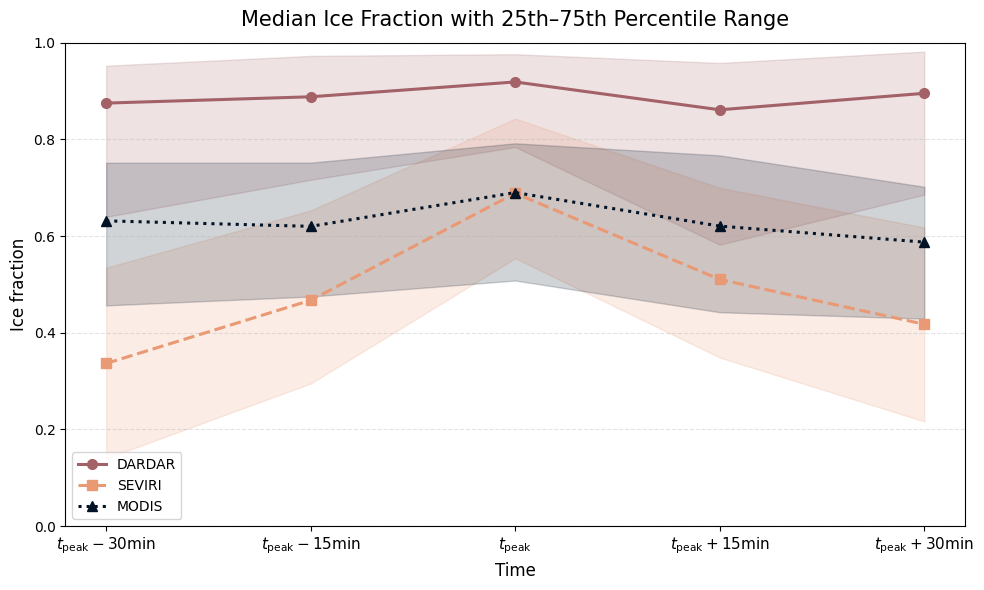

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order

timesteps = [i for i in range(2, -3, -1)]

# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    # r"$t_{\mathrm{peak}}-45\mathrm{min}$",
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$",
    # r"$t_{\mathrm{peak}}+45\mathrm{min}$",
]


def clean_vals(series):
    # vals = series.dropna()
    vals = series
    vals = vals[(vals >= 0) & (vals <= 1)]
    return vals.values

def median_q25_q75(vals):
    if len(vals) == 0:
        return np.nan, np.nan, np.nan
    q25 = np.percentile(vals, 25)
    med = np.percentile(vals, 50)
    q75 = np.percentile(vals, 75)
    return q25, med, q75

# store percentile stats
dardar_q25, dardar_med, dardar_q75 = [], [], []
seviri_q25, seviri_med, seviri_q75 = [], [], []
modis_q25, modis_med, modis_q75 = [], [], []

for dd_col, sev_col, mod_col in zip(dardar_cols, seviri_cols, modis_cols):
    # DARDAR
    dd_vals = clean_vals(df_glac_dd[dd_col])
    q25, med, q75 = median_q25_q75(dd_vals)
    dardar_q25.append(q25)
    dardar_med.append(med)
    dardar_q75.append(q75)

    # SEVIRI
    sev_vals = clean_vals(df_glac_mod[sev_col])
    q25, med, q75 = median_q25_q75(sev_vals)
    seviri_q25.append(q25)
    seviri_med.append(med)
    seviri_q75.append(q75)

    # MODIS
    mod_vals = clean_vals(df_glac_mod[mod_col])
    q25, med, q75 = median_q25_q75(mod_vals)
    modis_q25.append(q25)
    modis_med.append(med)
    modis_q75.append(q75)

# convert to arrays
dardar_q25 = np.array(dardar_q25)
dardar_med = np.array(dardar_med)
dardar_q75 = np.array(dardar_q75)

seviri_q25 = np.array(seviri_q25)
seviri_med = np.array(seviri_med)
seviri_q75 = np.array(seviri_q75)

modis_q25 = np.array(modis_q25)
modis_med = np.array(modis_med)
modis_q75 = np.array(modis_q75)

x = np.arange(len(x_labels))

plt.figure(figsize=(10, 6))

# median lines
line1, = plt.plot(
    x, dardar_med,
    marker="o", linestyle="-", linewidth=2.2, markersize=7,
    label="DARDAR", color = color_dd
)

line2, = plt.plot(
    x, seviri_med,
    marker="s", linestyle="--", linewidth=2.2, markersize=7,
    label="SEVIRI", color = color_sev
)

line3, = plt.plot(
    x, modis_med,
    marker="^", linestyle=":", linewidth=2.2, markersize=7,
    label="MODIS", color = color_mod
)

# shaded percentile bands
plt.fill_between(
    x, dardar_q25, dardar_q75,
    color=line1.get_color(), alpha=0.18
)

plt.fill_between(
    x, seviri_q25, seviri_q75,
    color=line2.get_color(), alpha=0.18
)

plt.fill_between(
    x, modis_q25, modis_q75,
    color=line3.get_color(), alpha=0.18
)

plt.xticks(x, x_labels, fontsize=11)
plt.ylabel("Ice fraction", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Median Ice Fraction with 25th–75th Percentile Range", fontsize=15, pad=12)

plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

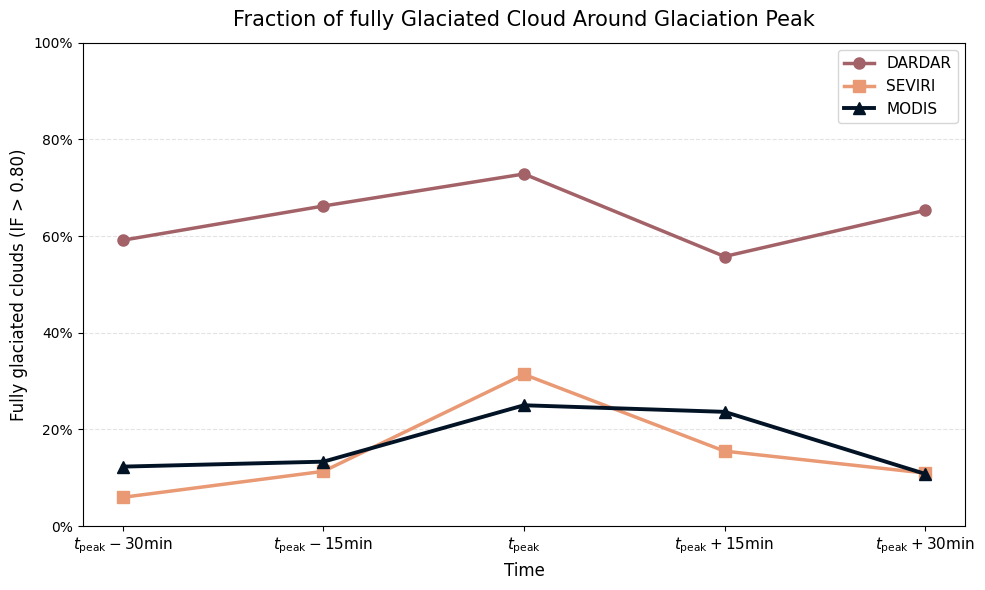

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# timesteps in plotting order
timesteps = [i for i in range(2, -3, -1)]

ice_phase_thresh = 0.8
eps=1e-4
# corresponding column names
dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

x_labels = [
    r"$t_{\mathrm{peak}}-30\mathrm{min}$",
    r"$t_{\mathrm{peak}}-15\mathrm{min}$",
    r"$t_{\mathrm{peak}}$",
    r"$t_{\mathrm{peak}}+15\mathrm{min}$",
    r"$t_{\mathrm{peak}}+30\mathrm{min}$"
]
x = np.arange(len(x_labels))

dardar_frac, seviri_frac, modis_frac = [], [], []
dardar_n, seviri_n, modis_n = [], [], []

for dd_col, sev_col, mod_col in zip(dardar_cols, seviri_cols, modis_cols):
    # DARDAR
    dd_vals = df_glac_dd[dd_col].dropna()
    dd_vals = dd_vals[(dd_vals >= 0) & (dd_vals <= 1)]
    dardar_frac.append((dd_vals >= ice_phase_thresh).mean() if len(dd_vals) > 0 else np.nan)
    dardar_n.append(len(dd_vals))

    # SEVIRI
    sev_vals = df_glac_mod[sev_col].dropna()
    sev_vals = sev_vals[(sev_vals >= 0-eps) & (sev_vals <= 1+eps)]
    seviri_frac.append((sev_vals >= ice_phase_thresh).mean() if len(sev_vals) > 0 else np.nan)
    seviri_n.append(len(sev_vals))

    # MODIS
    mod_vals = df_glac_mod[mod_col].dropna()
    mod_vals = mod_vals[(mod_vals >= 0) & (mod_vals <= 1)]
    modis_frac.append((mod_vals >= ice_phase_thresh).mean() if len(mod_vals) > 0 else np.nan)
    modis_n.append(len(mod_vals))

dardar_frac = np.array(dardar_frac)
seviri_frac = np.array(seviri_frac)
modis_frac = np.array(modis_frac)

plt.figure(figsize=(10, 6))

plt.plot(
    x, dardar_frac,
    marker="o", linestyle="-", linewidth=2.5, markersize=8,
    label="DARDAR", color = color_dd
)

plt.plot(
    x, seviri_frac,
    marker="s", linestyle="-", linewidth=2.5, markersize=8,
    label="SEVIRI", color = color_sev
)

plt.plot(
    x, modis_frac,
    marker="^", linestyle="-", linewidth=2.8, markersize=8,
    label="MODIS", color = color_mod
)

# optional point labels with different offsets to avoid overlap
# for xi, y in zip(x, dardar_frac):
#     if not np.isnan(y):
#         plt.text(xi, y + 0.025, f"{y:.2f}", ha="center", va="bottom", fontsize=9)

# for xi, y in zip(x, seviri_frac):
#     if not np.isnan(y):
#         plt.text(xi, y - 0.035, f"{y:.2f}", ha="center", va="top", fontsize=9)

# for xi, y in zip(x, modis_frac):
#     if not np.isnan(y):
#         plt.text(xi, y + 0.055, f"{y:.2f}", ha="center", va="bottom", fontsize=9)

plt.xticks(x, x_labels, fontsize=11)
# plt.ylabel(f"Fraction of fully glaciated clouds (IF > {ice_phase_thresh:.2f})", fontsize=12)
plt.xlabel("Time", fontsize=12)
plt.title("Fraction of fully Glaciated Cloud Around Glaciation Peak", fontsize=15, pad=12)
plt.ylabel(
    f"Fully glaciated clouds (IF > {ice_phase_thresh:.2f})",
    fontsize=12
)

plt.ylim(0, 1)
plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1))
# plt.ylim(0, 1)
plt.xlim(-0.2, len(x_labels) - 0.8)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()


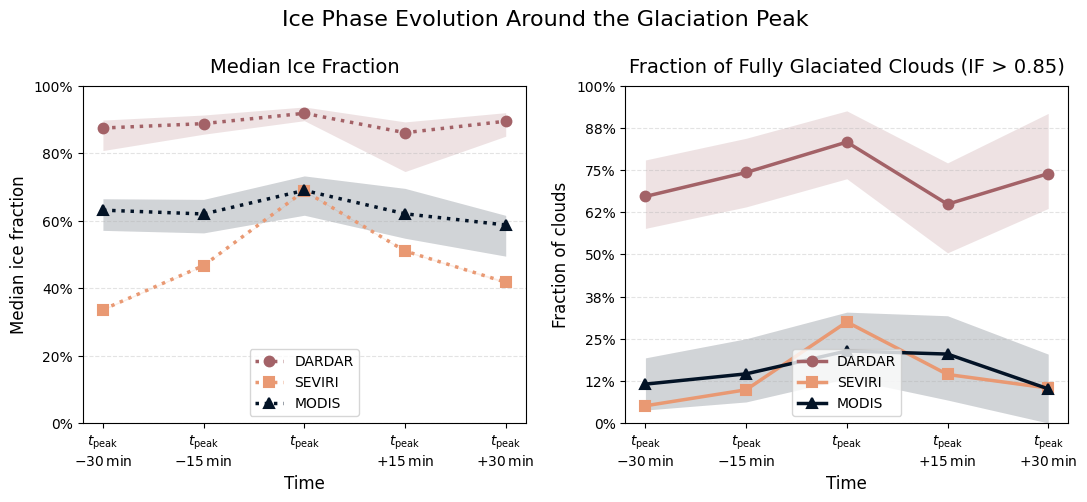

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
timesteps = list(range(2, -3, -1))
ice_phase_thresh = 0.85

n_bootstrap = 100
confidence_level = 90
random_seed = 42

dardar_cols = [f"val_{i}_prepeak_if" for i in timesteps]
modis_cols  = [f"val_{i}_prepeak_if" for i in timesteps]
seviri_cols = [f"seviri_{i}_prepeak_if" for i in timesteps]

# x_labels = [
#     r"$t_{\mathrm{peak}}\n-30\mathrm{min}$",
#     r"$t_{\mathrm{peak}}-15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}$",
#     r"$t_{\mathrm{peak}}+15\mathrm{min}$",
#     r"$t_{\mathrm{peak}}+30\mathrm{min}$",
# ]
x_labels = [
    "$t_{\\mathrm{peak}}$\n$-30\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$-15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$",
    "$t_{\\mathrm{peak}}$\n$+15\\,\\mathrm{min}$",
    "$t_{\\mathrm{peak}}$\n$+30\\,\\mathrm{min}$",
]

x = np.arange(len(x_labels))

# A single reproducible random-number generator
rng = np.random.default_rng(random_seed)

eps=1e-4
# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def clean_vals(series):
    """Remove missing and invalid ice-fraction values."""
    vals = series.dropna()
    # vals = series
    vals = vals[(vals >= 0-eps) & (vals <= 1+eps)]
    return vals.to_numpy()


def bootstrap_confidence_intervals(
    vals,
    threshold,
    n_bootstrap=5000,
    confidence_level=95,
    rng=None,
):
    """
    Calculate percentile-bootstrap confidence intervals for:

    1. Median ice fraction
    2. Fraction of values above the glaciation threshold
    """
    if len(vals) == 0:
        return np.nan, np.nan, np.nan, np.nan

    if rng is None:
        rng = np.random.default_rng()

    n = len(vals)

    # Shape: (number of bootstrap samples, original sample size)
    bootstrap_indices = rng.integers(
        low=0,
        high=n,
        size=(n_bootstrap, n),
    )
    bootstrap_samples = vals[bootstrap_indices]

    # Bootstrap distributions
    bootstrap_medians = np.median(bootstrap_samples, axis=1)
    bootstrap_fractions = np.mean(
        bootstrap_samples > threshold,
        axis=1,
    )

    alpha = (100 - confidence_level) / 2

    median_low, median_high = np.percentile(
        bootstrap_medians,
        [alpha, 100 - alpha],
    )

    fraction_low, fraction_high = np.percentile(
        bootstrap_fractions,
        [alpha, 100 - alpha],
    )

    return (
        median_low,
        median_high,
        fraction_low,
        fraction_high,
    )


def calculate_stats(
    df,
    columns,
    threshold,
    n_bootstrap=5000,
    confidence_level=95,
    rng=None,
):
    """Calculate point estimates and bootstrap confidence intervals."""
    median_values = []
    glaciated_fractions = []

    median_ci_low = []
    median_ci_high = []

    fraction_ci_low = []
    fraction_ci_high = []

    sample_sizes = []

    for column in columns:
        vals = clean_vals(df[column])
        sample_sizes.append(len(vals))

        if len(vals) == 0:
            median_values.append(np.nan)
            glaciated_fractions.append(np.nan)

            median_ci_low.append(np.nan)
            median_ci_high.append(np.nan)

            fraction_ci_low.append(np.nan)
            fraction_ci_high.append(np.nan)

            continue

        # Point estimates
        median_values.append(np.median(vals))
        glaciated_fractions.append(np.mean(vals > threshold))

        # Bootstrap confidence intervals
        med_low, med_high, frac_low, frac_high = (
            bootstrap_confidence_intervals(
                vals=vals,
                threshold=threshold,
                n_bootstrap=n_bootstrap,
                confidence_level=confidence_level,
                rng=rng,
            )
        )

        median_ci_low.append(med_low)
        median_ci_high.append(med_high)

        fraction_ci_low.append(frac_low)
        fraction_ci_high.append(frac_high)

    return {
        "median": np.asarray(median_values),
        "median_ci_low": np.asarray(median_ci_low),
        "median_ci_high": np.asarray(median_ci_high),
        "fraction": np.asarray(glaciated_fractions),
        "fraction_ci_low": np.asarray(fraction_ci_low),
        "fraction_ci_high": np.asarray(fraction_ci_high),
        "n": np.asarray(sample_sizes),
    }


# ------------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------------
dardar = calculate_stats(
    df=df_glac_dd,
    columns=dardar_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)

seviri = calculate_stats(
    df=df_glac_mod,
    columns=seviri_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)

modis = calculate_stats(
    df=df_glac_mod,
    columns=modis_cols,
    threshold=ice_phase_thresh,
    n_bootstrap=n_bootstrap,
    confidence_level=confidence_level,
    rng=rng,
)


# ------------------------------------------------------------------
# Dataset appearance
# ------------------------------------------------------------------
datasets = {
    "DARDAR": {
        "stats": dardar,
        "color": color_dd,
        "marker": "o",
    },
    "SEVIRI": {
        "stats": seviri,
        "color": color_sev,
        "marker": "s",
    },
    "MODIS": {
        "stats": modis,
        "color": color_mod,
        "marker": "^",
    },
}


# ------------------------------------------------------------------
# Two-panel plot
# ------------------------------------------------------------------
fig, (ax_med, ax_frac) = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(11, 5),
    sharex=True,
    # sharey=True,
)

for name, config in datasets.items():
    stats = config["stats"]
    color = config["color"]
    marker = config["marker"]

    # --------------------------------------------------------------
    # Top subplot: median ice fraction
    # --------------------------------------------------------------
    ax_med.fill_between(
        x,
        stats["median_ci_low"],
        stats["median_ci_high"],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

    ax_med.plot(
        x,
        stats["median"],
        color=color,
        marker=marker,
        linestyle=":",
        linewidth=2.5,
        markersize=7,
        markeredgewidth=1.5,
        label=name,
        zorder=3,
    )

    # --------------------------------------------------------------
    # Bottom subplot: fraction fully glaciated
    # --------------------------------------------------------------
    ax_frac.fill_between(
        x,
        stats["fraction_ci_low"],
        stats["fraction_ci_high"],
        color=color,
        alpha=0.18,
        linewidth=0,
        zorder=1,
    )

    ax_frac.plot(
        x,
        stats["fraction"],
        color=color,
        marker=marker,
        linestyle="-",
        linewidth=2.5,
        markersize=7,
        markeredgewidth=1.5,
        label=name,
        zorder=3,
    )


# ------------------------------------------------------------------
# Formatting
# ------------------------------------------------------------------
ax_med.set_title(
    "Median Ice Fraction",
    fontsize=14,
    pad=10,
)

ax_frac.set_title(
    fr"Fraction of Fully Glaciated Clouds (IF > {ice_phase_thresh:.2f})",
    fontsize=14,
    pad=10,
)

ax_med.set_ylabel("Median ice fraction", fontsize=12)
ax_med.set_xlabel("Time", fontsize=12)

ax_frac.set_ylabel("Fraction of clouds", fontsize=12)
ax_frac.set_xlabel("Time", fontsize=12)

ax_frac.set_ylim(0, 0.8)
ax_frac.yaxis.set_major_formatter(
        PercentFormatter(xmax=0.8)
    )
ax_med.set_ylim(0, 1.0)
ax_med.yaxis.set_major_formatter(
        PercentFormatter(xmax=1)
    )


for ax in (ax_med, ax_frac):
    ax.set_xlim(-0.2, len(x_labels) - 0.8)
    
    

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.35,
    )

    ax.legend(
        # title=f"{confidence_level}% bootstrap CI",
        loc="lower center",
        frameon=True,
    )


ax_frac.set_xticks(x)
ax_frac.set_xticklabels(x_labels, fontsize=10)

fig.suptitle(
    "Ice Phase Evolution Around the Glaciation Peak",
    fontsize=16,
    y=0.995,
)

fig.tight_layout()
fig.savefig(
    "/wolke_scratch/dnikolo/MSGI/plotting/Publication_figures/Multisatellite_IF.pdf",
    format="pdf",
    dpi=300
)
plt.show()

In [38]:
eps=1e-4
for col in dardar_cols:
    raw = pd.to_numeric(df_glac_dd[col], errors="coerce").dropna()

    first = raw[raw.between(0, 1)]
    second = raw[raw.between(-eps, 1 + eps)]

    print(
        col,
        "above 1:", (raw > 1).sum(),
        "first n:", len(first),
        "first fraction:", (first >= 0.80).mean(),
        "second n:", len(second),
        "second fraction:", (second > 0.85).mean(),
    )

val_2_prepeak_if above 1: 0 first n: 93 first fraction: 0.5913978494623656 second n: 93 second fraction: 0.5376344086021505
val_1_prepeak_if above 1: 0 first n: 74 first fraction: 0.6621621621621622 second n: 74 second fraction: 0.5945945945945946
val_0_prepeak_if above 1: 0 first n: 81 first fraction: 0.7283950617283951 second n: 81 second fraction: 0.6666666666666666
val_-1_prepeak_if above 1: 0 first n: 52 first fraction: 0.5576923076923077 second n: 52 second fraction: 0.5192307692307693
val_-2_prepeak_if above 1: 0 first n: 49 first fraction: 0.6530612244897959 second n: 49 second fraction: 0.5918367346938775
